<a href="https://colab.research.google.com/github/ttt-huong/helmet-detection-yolov8/blob/main/notebooks/01_Chuan_bi_va_khao_sat_du_lieu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Có CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
        "GB"
    )
else:
    print("Chưa được cấp GPU.")

!nvidia-smi
!df -h /content

Python: 3.13.16
PyTorch: 2.11.0+cu130
Có CUDA: True
GPU: Tesla T4
VRAM: 14.6 GB
Wed Nov  4 20:00:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                 

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import json
import sys
import torch
from datetime import datetime, timezone

PROJECT = Path("/content/drive/MyDrive/helmet_project")

for folder in [
    "notebooks", "configs", "data", "runs",
    "results/dataset_audit", "results/evaluation",
    "results/speed", "results/error_analysis",
    "demo", "report"
]:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

environment = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "pytorch": torch.__version__,
    "torch_cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "vram_gib": round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ),
}

env_path = PROJECT / "configs" / "environment_initial.json"
env_path.write_text(
    json.dumps(environment, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Thư mục dự án:", PROJECT)
print("Đã lưu thông tin môi trường:", env_path)
print("Kiểm tra đọc lại:", json.loads(env_path.read_text())["gpu"])

Thư mục dự án: /content/drive/MyDrive/helmet_project
Đã lưu thông tin môi trường: /content/drive/MyDrive/helmet_project/configs/environment_initial.json
Kiểm tra đọc lại: Tesla T4


In [ ]:
%pip -q install gdown

In [ ]:
from pathlib import Path
import gdown

RAW = Path("/content/helmet_raw")
RAW.mkdir(parents=True, exist_ok=True)

archive_path = RAW / "SHWD_download"

downloaded = gdown.download(
    id="1qWm7rrwvjAWs1slymbrLaCf7Q-wnGLEX",
    output=str(archive_path),
    quiet=False,
)

if downloaded is None:
    raise RuntimeError("Chưa tải được dataset. Dừng tại đây để kiểm tra.")

size_mb = archive_path.stat().st_size / 1024**2
print(f"Đã tải: {archive_path}")
print(f"Dung lượng: {size_mb:.1f} MB")

# Xác định loại file trước khi giải nén
!file /content/helmet_raw/SHWD_download

Downloading...
From (original): https://drive.google.com/uc?id=1qWm7rrwvjAWs1slymbrLaCf7Q-wnGLEX
From (redirected): https://drive.google.com/uc?id=1qWm7rrwvjAWs1slymbrLaCf7Q-wnGLEX&confirm=t&uuid=8d4c4c96-ff6f-44e5-96bb-1ecd1b1fb213
To: /content/helmet_raw/SHWD_download
100%|██████████| 1.12G/1.12G [00:25<00:00, 43.6MB/s]


Đã tải: /content/helmet_raw/SHWD_download
Dung lượng: 1066.2 MB
/content/helmet_raw/SHWD_download: Zip archive data, at least v2.0 to extract, compression method=store


In [ ]:
from pathlib import Path
from collections import Counter
import zipfile
import xml.etree.ElementTree as ET

archive = Path("/content/helmet_raw/SHWD_download")
extract_dir = Path("/content/helmet_raw/extracted")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive) as z:
    # Kiểm tra đường dẫn trước khi giải nén
    root = extract_dir.resolve()
    for member in z.infolist():
        target = (root / member.filename).resolve()
        if not target.is_relative_to(root):
            raise ValueError(f"Đường dẫn ZIP không hợp lệ: {member.filename}")

    print("Đang giải nén...")
    z.extractall(extract_dir)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
images = sorted(
    p for p in extract_dir.rglob("*")
    if p.suffix.lower() in image_extensions
)
xml_files = sorted(extract_dir.rglob("*.xml"))

class_counts = Counter()
xml_errors = []

for path in xml_files:
    try:
        tree = ET.parse(path)
        for obj in tree.getroot().findall("object"):
            class_counts[obj.findtext("name", default="").strip()] += 1
    except (ET.ParseError, OSError) as error:
        xml_errors.append((str(path), str(error)))

print("\nSố file ảnh:", len(images))
print("Số file XML:", len(xml_files))
print("Số box theo tên lớp:", dict(class_counts))
print("Số XML không đọc được:", len(xml_errors))

print("\nThư mục chứa ảnh:")
for folder in sorted({str(p.parent) for p in images}):
    print(folder)

print("\nThư mục chứa nhãn:")
for folder in sorted({str(p.parent) for p in xml_files}):
    print(folder)

print("\nCác file chia tập có sẵn:")
for p in sorted(extract_dir.rglob("*.txt")):
    if "ImageSets" in p.parts:
        print(p.relative_to(extract_dir))

if xml_errors:
    print("\nVí dụ lỗi XML:", xml_errors[:3])

Đang giải nén...

Số file ảnh: 7581
Số file XML: 7581
Số box theo tên lớp: {'hat': 9044, 'person': 111514, 'dog': 3}
Số XML không đọc được: 0

Thư mục chứa ảnh:
/content/helmet_raw/extracted/VOC2028/JPEGImages

Thư mục chứa nhãn:
/content/helmet_raw/extracted/VOC2028/Annotations

Các file chia tập có sẵn:
VOC2028/ImageSets/Main/test.txt
VOC2028/ImageSets/Main/train.txt
VOC2028/ImageSets/Main/trainval.txt
VOC2028/ImageSets/Main/val.txt


In [ ]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd
from PIL import Image

BASE = Path("/content/helmet_raw/extracted/VOC2028")
IMG, ANN, SETS = BASE/"JPEGImages", BASE/"Annotations", BASE/"ImageSets/Main"
OUT = Path("/content/drive/MyDrive/helmet_project/results/dataset_audit")
OUT.mkdir(parents=True, exist_ok=True)

# 1) Các tập chia sẵn
splits = {n: [l.strip() for l in (SETS/f"{n}.txt").read_text().splitlines() if l.strip()]
          for n in ["train", "val", "test", "trainval"]}
for n, ids in splits.items():
    print(f"{n}: {len(ids)} (duy nhất: {len(set(ids))})")
tr, va, te = (set(splits[k]) for k in ["train", "val", "test"])
print("train∩val:", len(tr & va), "| train∩test:", len(tr & te), "| val∩test:", len(va & te))
print("trainval == train ∪ val:", set(splits["trainval"]) == (tr | va))

stem2img = {p.stem: p for p in IMG.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}}
in_splits = tr | va | te
print("Ảnh không thuộc tập nào:", len(set(stem2img) - in_splits))
print("ID trong tập nhưng thiếu ảnh:", len(in_splits - set(stem2img)))

# 2) Đọc nhãn
rows, no_obj, size_mismatch = [], [], 0
for xp in sorted(ANN.glob("*.xml")):
    root = ET.parse(xp).getroot()
    W = int(float(root.findtext("size/width", "0")))
    H = int(float(root.findtext("size/height", "0")))
    imgp = stem2img.get(xp.stem)
    if imgp is not None:
        with Image.open(imgp) as im:
            if im.size != (W, H):
                size_mismatch += 1
                W, H = im.size          # dùng kích thước thật của ảnh
    objs = root.findall("object")
    if not objs:
        no_obj.append(xp.stem)
    for o in objs:
        bb = o.find("bndbox")
        x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
        rows.append(dict(id=xp.stem, cls=o.findtext("name").strip(), W=W, H=H,
                         x1=x1, y1=y1, x2=x2, y2=y2, difficult=o.findtext("difficult")))
df = pd.DataFrame(rows)
df["split"] = df["id"].map(lambda i: "train" if i in tr else "val" if i in va else "test" if i in te else "none")
df["bw"], df["bh"] = df.x2 - df.x1, df.y2 - df.y1
df["long_px_640"] = df[["bw", "bh"]].max(axis=1) * 640 / df[["W", "H"]].max(axis=1)

print("\nẢnh không có box:", len(no_obj), "| XML lệch kích thước so với ảnh thật:", size_mismatch)
print("Box lỗi (x2<=x1 hoặc y2<=y1):", int(((df.bw <= 0) | (df.bh <= 0)).sum()))
print("Box ra ngoài ảnh:", int(((df.x1 < 0) | (df.y1 < 0) | (df.x2 > df.W) | (df.y2 > df.H)).sum()))
print("Giá trị difficult:", df.difficult.value_counts(dropna=False).to_dict())

# 3) Thống kê theo tập và lớp
print("\nSố box theo tập và lớp:")
print(pd.crosstab(df.split, df.cls, margins=True))
print("\nSố ảnh có ít nhất một box của lớp, theo tập:")
print(df.groupby(["split", "cls"])["id"].nunique().unstack(fill_value=0))
per_img = df.groupby("id").size()
print("\nSố box mỗi ảnh:\n", per_img.describe().round(1))
print("5 ảnh đông nhất:", per_img.sort_values(ascending=False).head(5).to_dict())
print("\nKích thước cạnh dài của box (quy về ảnh 640 px), theo lớp:")
print(df.groupby("cls")["long_px_640"].describe(percentiles=[.1, .5, .9]).round(1))

print("\nẢnh chứa dog:", df[df.cls == "dog"]["id"].tolist())
df.to_csv(OUT / "boxes_raw.csv", index=False)
print("Đã lưu:", OUT / "boxes_raw.csv")

train: 5457 (duy nhất: 5457)
val: 607 (duy nhất: 607)
test: 1517 (duy nhất: 1517)
trainval: 6064 (duy nhất: 6064)
train∩val: 0 | train∩test: 0 | val∩test: 0
trainval == train ∪ val: True
Ảnh không thuộc tập nào: 0
ID trong tập nhưng thiếu ảnh: 0

Ảnh không có box: 0 | XML lệch kích thước so với ảnh thật: 0
Box lỗi (x2<=x1 hoặc y2<=y1): 0
Box ra ngoài ảnh: 0
Giá trị difficult: {'0': 119951, '1': 610}

Số box theo tập và lớp:
cls    dog   hat  person     All
split                           
test     0  1878   22558   24436
train    3  6419   79778   86200
val      0   747    9178    9925
All      3  9044  111514  120561

Số ảnh có ít nhất một box của lớp, theo tập:
cls    dog   hat  person
split                   
test     0   663     947
train    1  2274    3479
val      0   282     369

Số box mỗi ảnh:
 count    7581.0
mean       15.9
std        22.8
min         1.0
25%         2.0
50%         6.0
75%        17.0
max       162.0
dtype: float64
5 ảnh đông nhất: {'PartB_00053': 162, '001

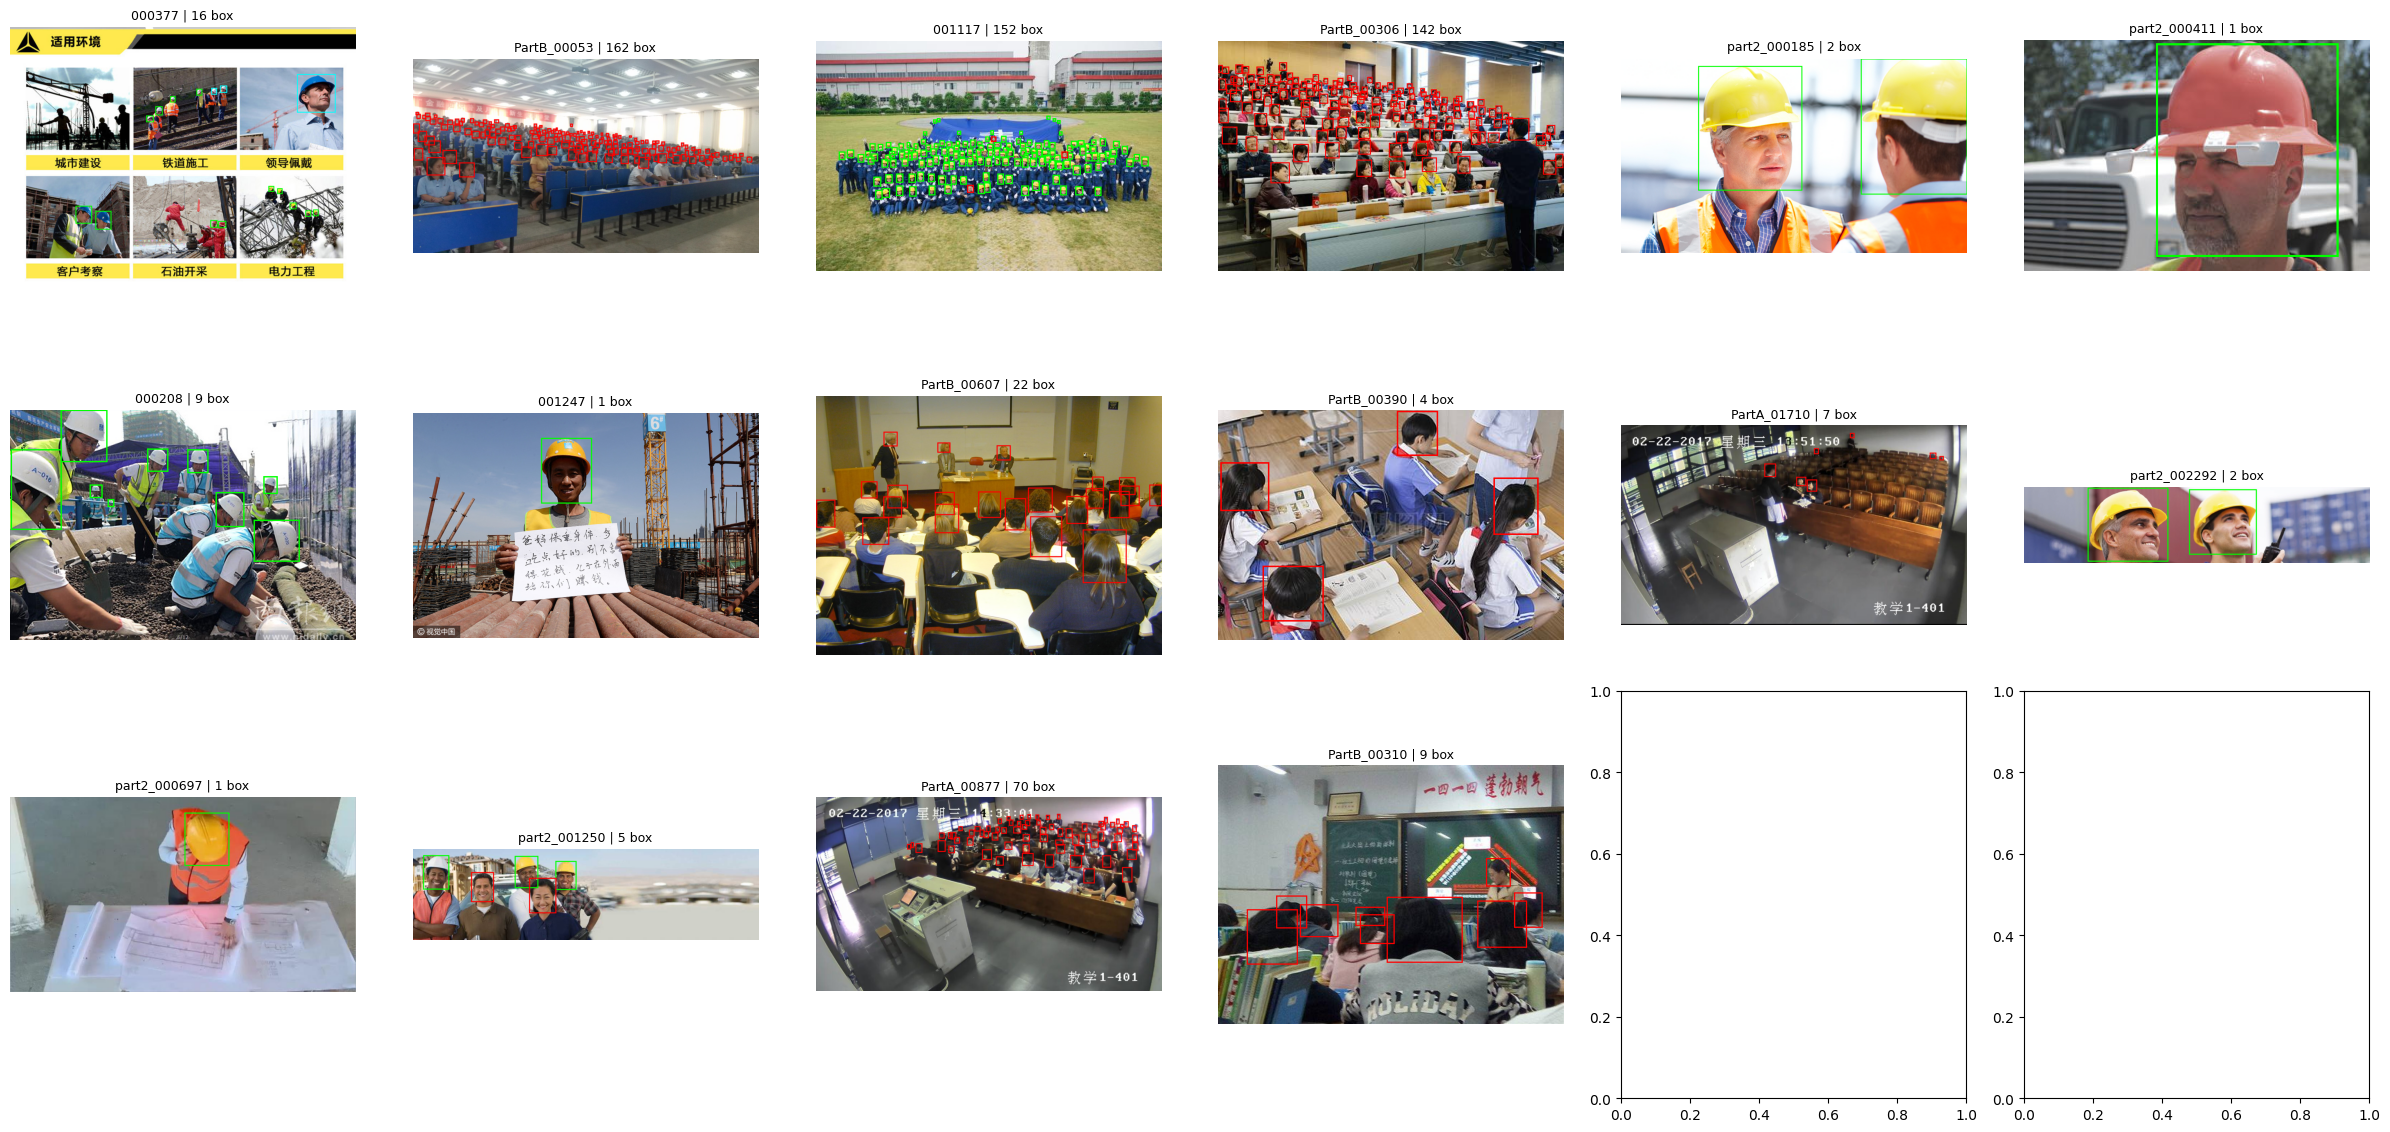

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import ImageDraw

random.seed(0)
COLORS = {"hat": "lime", "person": "red", "dog": "cyan"}
by_id = df.groupby("id")
dog_ids = df[df.cls == "dog"]["id"].unique().tolist()
crowded = per_img.sort_values(ascending=False).head(3).index.tolist()
hat_few_person = [i for i, g in by_id if (g.cls == "hat").any() and (g.cls == "person").sum() <= 2]
all_ids_list = sorted(stem2img)
picks = (dog_ids[:3] + crowded +
         random.sample(hat_few_person, min(4, len(hat_few_person))) +
         random.sample(all_ids_list, 8))[:18]

def draw(i):
    im = Image.open(stem2img[i]).convert("RGB")
    d = ImageDraw.Draw(im)
    lw = max(2, im.width // 300)
    for _, r in by_id.get_group(i).iterrows():
        d.rectangle([r.x1, r.y1, r.x2, r.y2], outline=COLORS.get(r.cls, "yellow"), width=lw)
    return im

fig, axes = plt.subplots(3, 6, figsize=(24, 12))
for ax, i in zip(axes.ravel(), picks):
    ax.imshow(draw(i)); ax.set_title(f"{i} | {len(by_id.get_group(i))} box", fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "sample_labels.png", dpi=110)
plt.show()

Số ảnh theo nguồn và tập:
split    test  train  val
source                   
PartA     382   1459  158
PartB     468   1707  166
numeric   325   1145  138
part2     342   1146  145

Số box theo nguồn và lớp:
cls      dog   hat  person
source                    
PartA      0     0   67318
PartB      0     0   42689
numeric    3  5255    1198
part2      0  3789     309

hat: <4px=0.2% | <16px=9.0% | <32px=25.8%

person: <4px=0.0% | <16px=48.8% | <32px=79.7%

difficult theo lớp:
 difficult       0    1
cls                   
dog             0    3
hat          8437  607
person     111514    0


100%|██████████| 7581/7581 [02:03<00:00, 61.25it/s]



Cặp test~train (Hamming<=4): 15452 | ảnh test bị ảnh hưởng: 402/1517
Cặp val~train  (Hamming<=4): 6810 | ảnh val bị ảnh hưởng:  172/607
Trùng hệt (d=0) test~train: 761
Theo nguồn của ảnh test bị ảnh hưởng: {'PartA': 15410, 'part2': 16, 'numeric': 13, 'PartB': 13}


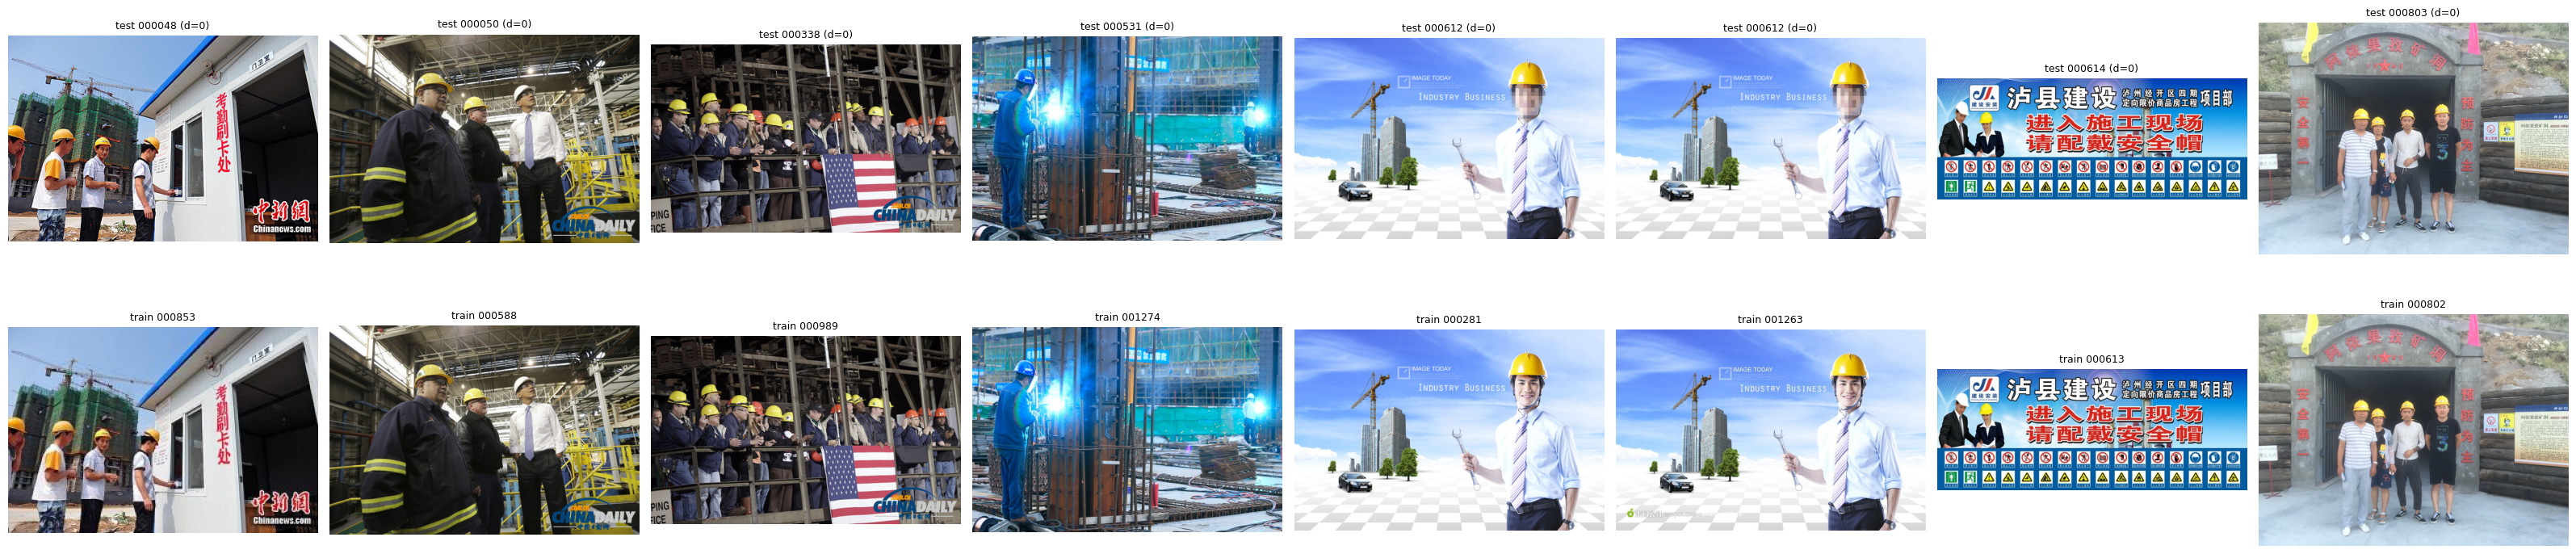

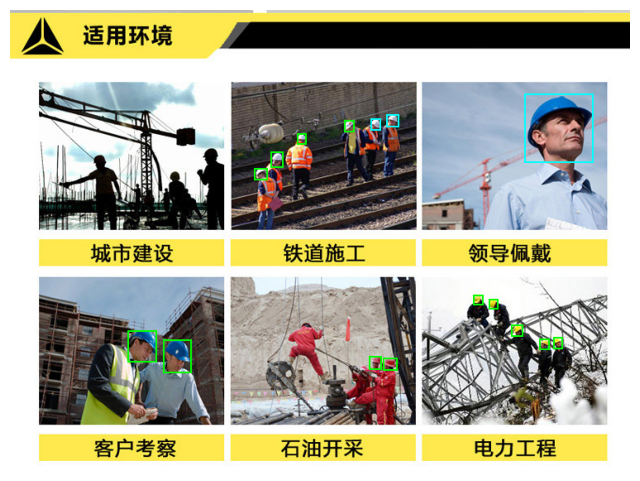

In [ ]:
%pip -q install imagehash
import re, numpy as np, imagehash
from tqdm import tqdm

# 1) Nguồn ảnh suy từ tiền tố ID (PartA_, PartB_, part2_, hoặc toàn số)
def source(i):
    m = re.match(r"^([A-Za-z0-9]+)_", i)
    return m.group(1) if m else "numeric"
df["source"] = df["id"].map(source)
print("Số ảnh theo nguồn và tập:")
print(df.drop_duplicates("id").groupby(["source", "split"]).size().unstack(fill_value=0))
print("\nSố box theo nguồn và lớp:")
print(pd.crosstab(df.source, df.cls))

# 2) Mức nhỏ của box theo lớp (quy về ảnh 640 px)
for c in ["hat", "person"]:
    s = df[df.cls == c]["long_px_640"]
    print(f"\n{c}: <4px={(s<4).mean():.1%} | <16px={(s<16).mean():.1%} | <32px={(s<32).mean():.1%}")
print("\ndifficult theo lớp:\n", pd.crosstab(df.cls, df.difficult))

# 3) Perceptual hash cho mọi ảnh
ids_all = sorted(stem2img)
hashes = {}
for i in tqdm(ids_all):
    with Image.open(stem2img[i]) as im:
        hashes[i] = np.uint64(int(str(imagehash.phash(im)), 16))

POP = np.array([bin(k).count("1") for k in range(256)], dtype=np.uint8)
def hamming(arr, h):
    x = np.bitwise_xor(arr, h)
    return POP[x.view(np.uint8).reshape(-1, 8)].sum(1)

def cross(a_ids, b_ids, thr=4):
    B = np.array([hashes[i] for i in b_ids], dtype=np.uint64)
    out = []
    for i in a_ids:
        d = hamming(B, hashes[i])
        for j in np.where(d <= thr)[0]:
            out.append((i, b_ids[j], int(d[j])))
    return out

tr_l, va_l, te_l = sorted(tr), sorted(va), sorted(te)
tt = cross(te_l, tr_l)
vt = cross(va_l, tr_l)
print(f"\nCặp test~train (Hamming<=4): {len(tt)} | ảnh test bị ảnh hưởng: {len({a for a,_,_ in tt})}/{len(te_l)}")
print(f"Cặp val~train  (Hamming<=4): {len(vt)} | ảnh val bị ảnh hưởng:  {len({a for a,_,_ in vt})}/{len(va_l)}")
print("Trùng hệt (d=0) test~train:", sum(1 for *_, d in tt if d == 0))
print("Theo nguồn của ảnh test bị ảnh hưởng:",
      pd.Series([source(a) for a, _, _ in tt]).value_counts().to_dict())

# 4) Xem 8 cặp test~train gần giống nhất và ảnh 000377
show = sorted(tt, key=lambda t: t[2])[:8]
fig, axes = plt.subplots(2, 8, figsize=(32, 8))
for k, (a, b, d) in enumerate(show):
    axes[0, k].imshow(Image.open(stem2img[a])); axes[0, k].set_title(f"test {a} (d={d})", fontsize=9)
    axes[1, k].imshow(Image.open(stem2img[b])); axes[1, k].set_title(f"train {b}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "near_duplicates.png", dpi=90); plt.show()

plt.figure(figsize=(8, 8)); plt.imshow(draw("000377")); plt.axis("off"); plt.show()


test ~ (train+val): số ảnh có bản gần giống theo ngưỡng
     tổng  PartA  PartB  numeric  part2
thr                                    
0     186    151     11        9     15
2     368    325     14       11     18
4     409    364     14       13     18
6     430    377     14       20     19
8     441    379     14       25     23
10    449    380     15       28     26

val ~ train: số ảnh có bản gần giống theo ngưỡng
     tổng  PartA  PartB  numeric  part2
thr                                    
0      76     56      5        9      6
2     159    137      6        9      7
4     172    149      6        9      8
6     182    157      6       10      9
8     187    158      7       11     11
10    187    158      7       11     11


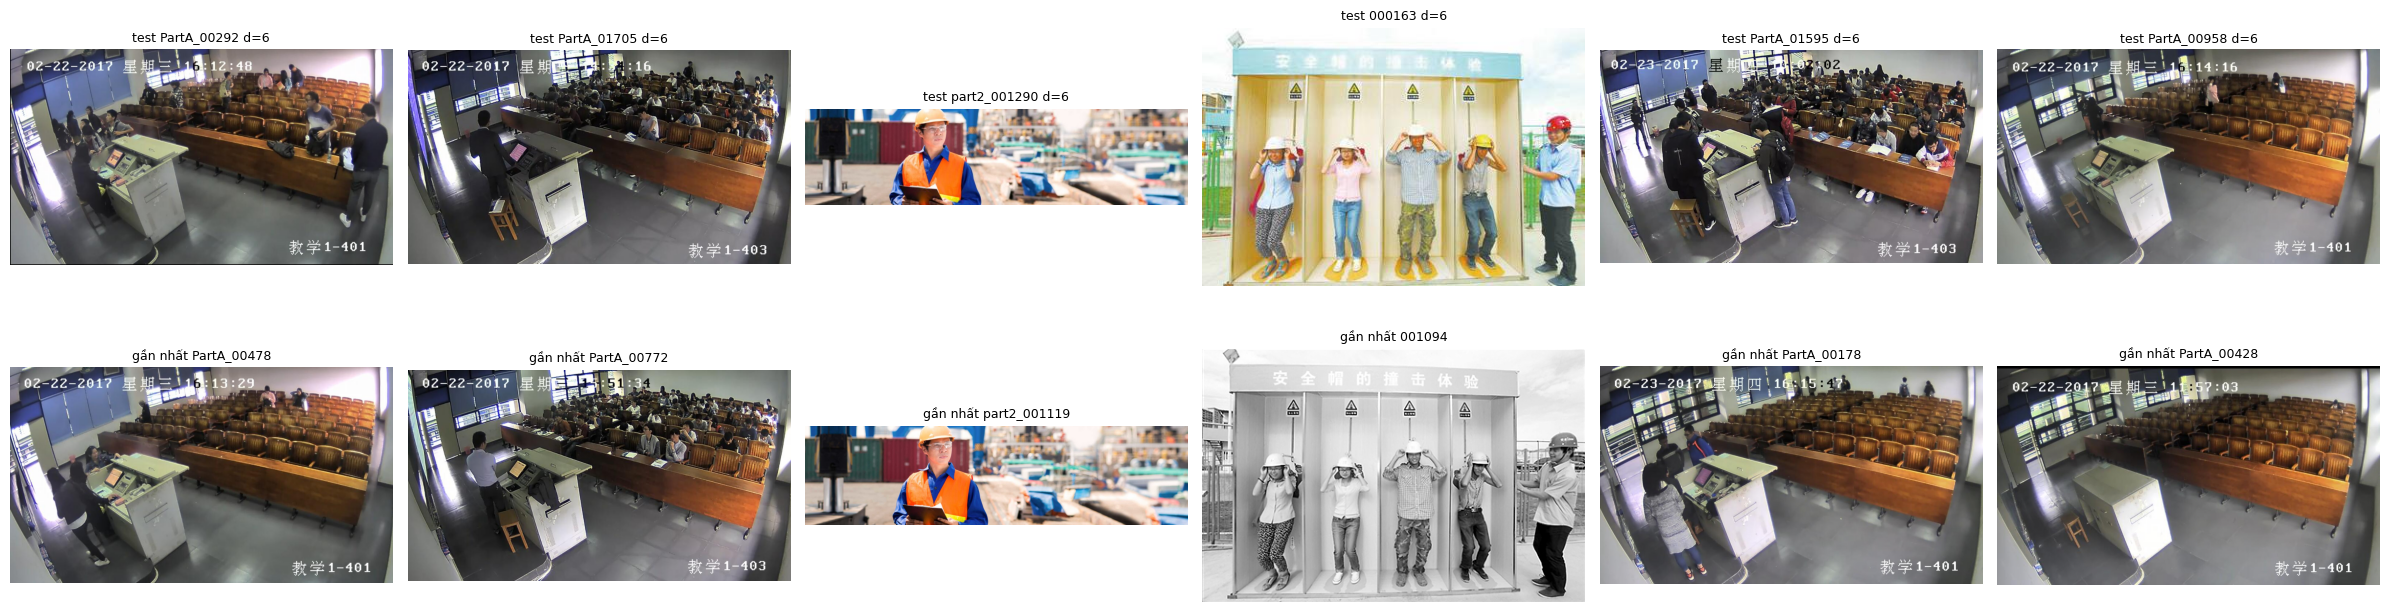


Ngưỡng=6: test 1517 -> 1087 | val 607 -> 425

train: 5457 ảnh
cls      dog   hat  person
source                    
PartA      0     0   48424
PartB      0     0   30342
numeric    3  3757     822
part2      0  2662     190

val_clean: 425 ảnh
cls      hat  person
source              
PartA      0      68
PartB      0    3488
numeric  365     105
part2    335      39

test_clean: 1087 ảnh
cls       hat  person
source               
PartA       0     118
PartB       0    8414
numeric  1020     257
part2     724      77

Ảnh có 'person' trong nhóm ảnh có mũ, theo tập gốc: {'test': 97, 'train': 313, 'val': 45}


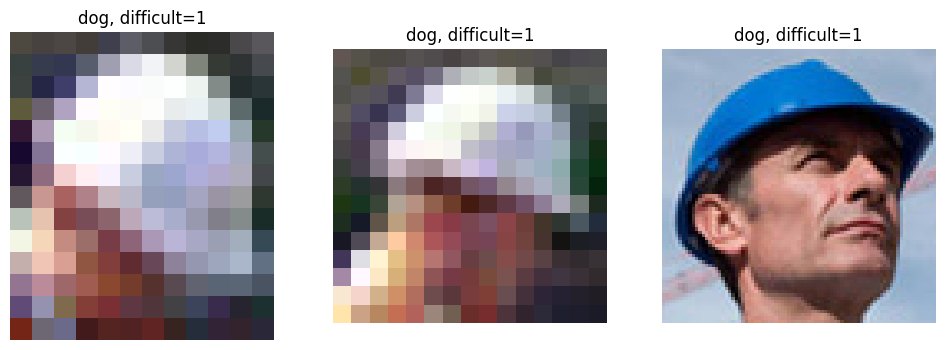

In [ ]:
import numpy as np, pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/helmet_project")
MAN = PROJECT / "data" / "manifests"; MAN.mkdir(parents=True, exist_ok=True)
src = {i: source(i) for i in ids_all}

def nearest(a_ids, b_ids):
    B = np.array([hashes[i] for i in b_ids], dtype=np.uint64)
    rec = []
    for i in a_ids:
        d = hamming(B, hashes[i]); k = int(d.argmin())
        rec.append((i, int(d[k]), b_ids[k]))
    return pd.DataFrame(rec, columns=["id", "d", "nn"]).set_index("id")

nt = nearest(te_l, sorted(tr | va))     # test so với train+val
nv = nearest(va_l, tr_l)                # val so với train

# 1) Độ nhạy theo ngưỡng Hamming
for name, nn_df in [("test ~ (train+val)", nt), ("val ~ train", nv)]:
    rows = []
    for thr in [0, 2, 4, 6, 8, 10]:
        flag = nn_df["d"] <= thr
        row = {"thr": thr, "tổng": int(flag.sum())}
        row.update(flag.groupby(nn_df.index.map(src)).sum().astype(int).to_dict())
        rows.append(row)
    print(f"\n{name}: số ảnh có bản gần giống theo ngưỡng")
    print(pd.DataFrame(rows).set_index("thr").fillna(0).astype(int))

# 2) Xem các cặp ở khoảng cách 5-6 để kiểm tra ngưỡng 6
cand = nt[(nt.d >= 5) & (nt.d <= 6)]
pick = cand.sample(min(6, len(cand)), random_state=0) if len(cand) else cand
if len(pick):
    fig, axes = plt.subplots(2, len(pick), figsize=(4 * len(pick), 7), squeeze=False)
    for k, (i, r) in enumerate(pick.iterrows()):
        axes[0, k].imshow(Image.open(stem2img[i])); axes[0, k].set_title(f"test {i} d={r.d}", fontsize=9)
        axes[1, k].imshow(Image.open(stem2img[r.nn])); axes[1, k].set_title(f"gần nhất {r.nn}", fontsize=9)
    for ax in axes.ravel(): ax.axis("off")
    plt.tight_layout(); plt.show()

# 3) Tạo danh sách sạch và lưu manifests
THR = 6
test_clean = [i for i in te_l if nt.loc[i, "d"] > THR]
val_clean  = [i for i in va_l if nv.loc[i, "d"] > THR]
for name, ids in {"train": tr_l, "val": va_l, "test": te_l,
                  "val_clean": val_clean, "test_clean": test_clean}.items():
    (MAN / f"{name}.txt").write_text("\n".join(ids))
nt.to_csv(MAN / "nearest_test_vs_trainval.csv"); nv.to_csv(MAN / "nearest_val_vs_train.csv")
print(f"\nNgưỡng={THR}: test {len(te_l)} -> {len(test_clean)} | val {len(va_l)} -> {len(val_clean)}")

for name, ids in [("train", tr_l), ("val_clean", val_clean), ("test_clean", test_clean)]:
    sub = df[df.id.isin(ids)]
    print(f"\n{name}: {len(ids)} ảnh"); print(pd.crosstab(sub.source, sub.cls))
site = df[df.source.isin(["numeric", "part2"]) & (df.cls == "person")]
print("\nẢnh có 'person' trong nhóm ảnh có mũ, theo tập gốc:", site.groupby("split")["id"].nunique().to_dict())

# 4) Xem 3 khung 'dog'
dg = df[df.cls == "dog"]
im = Image.open(stem2img["000377"]).convert("RGB")
fig, ax = plt.subplots(1, len(dg), figsize=(4 * len(dg), 4), squeeze=False)
for a, (_, r) in zip(ax[0], dg.iterrows()):
    a.imshow(im.crop((int(r.x1), int(r.y1), int(r.x2), int(r.y2)))); a.axis("off")
    a.set_title(f"dog, difficult={r.difficult}")
plt.show()

In [ ]:
import shutil, yaml
from pathlib import Path

YOLO = Path("/content/helmet_yolo")
(YOLO/"images").mkdir(parents=True, exist_ok=True)
(YOLO/"labels").mkdir(parents=True, exist_ok=True)
CFG = PROJECT/"configs"; MAN = PROJECT/"data"/"manifests"
CFG.mkdir(parents=True, exist_ok=True); MAN.mkdir(parents=True, exist_ok=True)

# 1) dog -> hat (3 box, đã xem crop: đều là đầu đội mũ)
d2 = df.copy()
d2.loc[d2.cls == "dog", "cls"] = "hat"
CLASS_ID = {"hat": 0, "person": 1}
NAMES = {0: "helmet", 1: "bare_head"}

# 2) Chuyển sang YOLO
for i, g in d2.groupby("id"):
    dst = YOLO/"images"/stem2img[i].name
    if not dst.exists():
        shutil.copy2(stem2img[i], dst)
    lines = [f"{CLASS_ID[r.cls]} {(r.x1+r.x2)/2/r.W:.6f} {(r.y1+r.y2)/2/r.H:.6f} "
             f"{(r.x2-r.x1)/r.W:.6f} {(r.y2-r.y1)/r.H:.6f}" for r in g.itertuples()]
    (YOLO/"labels"/f"{i}.txt").write_text("\n".join(lines) + "\n")

# 3) Danh sách ảnh theo tập và data.yaml
SITE = {"numeric", "part2"}
lists = {"train": tr_l, "val": va_l, "test": te_l,
         "val_clean": val_clean, "test_clean": test_clean,
         "val_clean_site": [i for i in val_clean if source(i) in SITE],
         "test_clean_site": [i for i in test_clean if source(i) in SITE]}
for name, ids in lists.items():
    (YOLO/f"{name}.txt").write_text("\n".join(str(YOLO/"images"/stem2img[i].name) for i in ids) + "\n")
    (MAN/f"{name}.txt").write_text("\n".join(ids))

def write_yaml(fname, tr, va, te):
    cfg = {"path": str(YOLO), "train": f"{tr}.txt", "val": f"{va}.txt", "test": f"{te}.txt", "names": NAMES}
    (YOLO/fname).write_text(yaml.safe_dump(cfg, sort_keys=False))
    shutil.copy(YOLO/fname, CFG/fname)
write_yaml("data.yaml", "train", "val_clean", "test_clean")
write_yaml("data_test_official.yaml", "train", "val_clean", "test")
write_yaml("data_test_clean_site.yaml", "train", "val_clean_site", "test_clean_site")

# 4) Kiểm tra
cnt, bad = {0: 0, 1: 0}, 0
for p in (YOLO/"labels").glob("*.txt"):
    for ln in p.read_text().splitlines():
        t = ln.split()
        if len(t) != 5 or int(t[0]) not in cnt or any(not (0 <= float(x) <= 1) for x in t[1:]):
            bad += 1
        else:
            cnt[int(t[0])] += 1
print("Ảnh:", len(list((YOLO/'images').iterdir())), "| file nhãn:", len(list((YOLO/'labels').glob('*.txt'))), "| dòng lỗi:", bad)
print("Box theo lớp (mong đợi {0: 9047, 1: 111514}):", cnt)
print("Đường dẫn ảnh không tồn tại:",
      sum(not Path(l).exists() for n in lists for l in (YOLO/f"{n}.txt").read_text().split()))
for name, ids in lists.items():
    sub = d2[d2.id.isin(ids)]
    print(f"{name:16s} {len(ids):5d} ảnh | hat={(sub.cls=='hat').sum():6d} person={(sub.cls=='person').sum():6d}")

Ảnh: 7581 | file nhãn: 7581 | dòng lỗi: 0
Box theo lớp (mong đợi {0: 9047, 1: 111514}): {0: 9047, 1: 111514}
Đường dẫn ảnh không tồn tại: 0
train             5457 ảnh | hat=  6422 person= 79778
val                607 ảnh | hat=   747 person=  9178
test              1517 ảnh | hat=  1878 person= 22558
val_clean          425 ảnh | hat=   700 person=  3700
test_clean        1087 ảnh | hat=  1744 person=  8866
val_clean_site     264 ảnh | hat=   700 person=   144
test_clean_site    628 ảnh | hat=  1744 person=   334


In [ ]:
import json, hashlib
sha = hashlib.sha256()
with open("/content/helmet_raw/SHWD_download", "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        sha.update(chunk)
(CFG/"dataset_source.json").write_text(json.dumps({
    "name": "SHWD (VOC2028)", "downloaded": "2026-11-03",
    "gdrive_id": "1qWm7rrwvjAWs1slymbrLaCf7Q-wnGLEX", "sha256": sha.hexdigest(),
    "license_checked": False}, indent=2))
(CFG/"label_rules.md").write_text(
    "- helmet (id 0): khung quanh mũ bảo hộ/đầu đội mũ; 3 box 'dog' đã đổi thành helmet.\n"
    "- bare_head (id 1): khung quanh đầu không đội mũ, không phải cả người.\n"
    "- Lọc trùng: pHash, Hamming <= 6; val_clean/test_clean loại ảnh gần giống train.\n")
print("Đã lưu")

Đã lưu


In [ ]:
%pip -q install ultralytics
import sys, subprocess, ultralytics
from ultralytics import YOLO as UL
print("Ultralytics:", ultralytics.__version__)
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(CFG/"pip_freeze.txt").write_text(freeze)

m = UL("yolov8n.pt")
img = str(YOLO/"images"/stem2img["000163"].name)
r = m.predict(img, conf=0.25, save=True,
              project=str(PROJECT/"results"/"smoke"), name="yolov8n_coco", exist_ok=True)
print("Số phát hiện:", len(r[0].boxes), "| lưu tại:", r[0].save_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.202

image 1/1 /content/helmet_yolo/images/000163.jpg: 448x640 5 persons, 9.6ms
Speed: 112.7ms preprocess, 9.6ms inference, 45.8ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/drive/MyDrive/helmet_project/results/smoke/yolov8n_coco
Số phát hiện: 5 | lưu tại: /content/drive/MyDrive/helmet_project/results/smoke/yolov8n_coco


In [ ]:
import time, shutil
from ultralytics import YOLO as UL

SMOKE = Path("/content/runs_smoke")
t0 = time.time()
m = UL("yolov8n.pt")
m.train(data=str(YOLO/"data.yaml"), epochs=3, imgsz=640, batch=16,
        seed=42, project=str(SMOKE), name="smoke_v8n", exist_ok=True)
print(f"\nTổng thời gian: {(time.time()-t0)/60:.1f} phút")

run = SMOKE/"smoke_v8n"
print("File trong thư mục run:", sorted(p.name for p in run.iterdir()))
print("File trọng số:", sorted(p.name for p in (run/"weights").iterdir()))
print(pd.read_csv(run/"results.csv").round(4).T.to_string())
shutil.copytree(run, PROJECT/"runs"/"smoke_v8n", dirs_exist_ok=True)
print("Đã chép lên Drive:", PROJECT/"runs"/"smoke_v8n")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_v8n, nbs=64, nms=None, opset=None, optimize=False, opti

In [ ]:
import time, torch, pandas as pd
from ultralytics import YOLO as UL

def probe(weights, frac=0.25, epochs=2, batch=16):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    name = "probe_" + weights.replace(".pt", "")
    m = UL(weights)
    m.train(data=str(YOLO/"data.yaml"), epochs=epochs, imgsz=640, batch=batch,
            fraction=frac, seed=42, project=str(SMOKE), name=name,
            exist_ok=True, plots=False)
    res = pd.read_csv(SMOKE/name/"results.csv")
    ep2 = res["time"].iloc[-1] - res["time"].iloc[-2]
    return dict(model=weights, batch=batch,
                peak_gb=round(torch.cuda.max_memory_reserved()/1024**3, 1),
                epoch2_s=round(ep2), est_full_epoch_s=round(ep2/frac),
                est_50ep_h=round(ep2/frac*50/3600, 1))

rows = []
for w in ["yolov8n.pt", "yolov8s.pt", "yolov8m.pt"]:
    try:
        rows.append(probe(w))
    except Exception as e:
        rows.append(dict(model=w, batch=16, lỗi=str(e)[:200]))
    print(rows[-1])
tbl = pd.DataFrame(rows)
print(tbl.to_string(index=False))
tbl.to_csv(PROJECT/"results"/"smoke"/"probe_timing.csv", index=False)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.25, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=probe_yolov8n, nbs=64, nms=None, opset=None, optimize=False,

In [ ]:
import pandas as pd
from ultralytics import YOLO as UL

# 1) Nạp lại mô hình đã lưu trên Drive và dự đoán 2 ảnh val_clean_site
saved = PROJECT/"runs"/"smoke_v8n"/"weights"/"best.pt"
m = UL(str(saved))
imgs = [str(YOLO/"images"/stem2img[i].name) for i in lists["val_clean_site"][:2]]
r = m.predict(imgs, conf=0.25, save=True,
              project=str(PROJECT/"results"/"smoke"), name="reload_check", exist_ok=True)
for res in r:
    print(Path(res.path).name, "->", {m.names[int(c)]: int((res.boxes.cls == c).sum()) for c in res.boxes.cls.unique()})

# 2) Giả lập bị ngắt sau epoch 1, rồi học tiếp từ last.pt
def stop_after_epoch_1(trainer):
    if trainer.epoch == 0:
        raise RuntimeError("Dừng giả lập sau epoch 1 (để thử học tiếp)")

t = UL("yolov8n.pt")
t.add_callback("on_fit_epoch_end", stop_after_epoch_1)
try:
    t.train(data=str(YOLO/"data.yaml"), epochs=3, imgsz=640, batch=16, fraction=0.1,
            seed=42, project=str(SMOKE), name="resume_test", exist_ok=True, plots=False)
except RuntimeError as e:
    print("\nĐã dừng:", e)

last = SMOKE/"resume_test"/"weights"/"last.pt"
print("last.pt tồn tại:", last.exists())
UL(str(last)).train(resume=True)
print(pd.read_csv(SMOKE/"resume_test"/"results.csv")[["epoch","metrics/mAP50(B)"]])


0: 640x640 1 helmet, 8.6ms
1: 640x640 1 helmet, 3 bare_heads, 8.6ms
Speed: 2.7ms preprocess, 8.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/helmet_project/results/smoke/reload_check
000000.jpg -> {'helmet': 1}
000009.jpg -> {'helmet': 1, 'bare_head': 3}
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/helmet_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=to